# Overfitting vs Underfitting: The Signal and Noise Perspective

Welcome to this tutorial on understanding overfitting and underfitting through the lens of **signal (information) and noise**.

## What You'll Learn
- **The fundamental insight**: Training data = Information + Noise
- **Why overfitting happens**: Learning noise alongside the signal
- **Why underfitting happens**: Not capturing all the information
- **Why generalization fails**: Test data has different noise
- **Interactive visualizations** to build intuition
- **Practical techniques** to achieve the right balance

---

## The Core Insight

**Every dataset contains two components:**

1. **Information (Signal)**: The true underlying pattern we want to learn
2. **Random Noise**: Measurement errors, natural variation, irreducible randomness

**The Challenge:**
- Training data: Information + Random Noise (sample 1)
- Test data: Same Information + **Different** Random Noise (sample 2)

**Our Goal:** Learn the information, ignore the noise.

| Scenario | What Model Learns | Train Performance | Test Performance |
|----------|------------------|-------------------|------------------|
| **Underfit** | Only part of the information | Poor | Poor |
| **Just Right** | All the information, no noise | Good | Good |
| **Overfit** | Information + Noise | Excellent | Poor |

---
## 1. Setup

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Interactive widgets
from ipywidgets import interact, IntSlider, FloatSlider, fixed

# Visualization settings
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# Set random seed for reproducibility
np.random.seed(42)

print("Libraries loaded successfully!")

Libraries loaded successfully!


---
## 2. Visualizing Data = Information + Noise

Let's start by clearly seeing how data is composed of a true signal plus random noise.

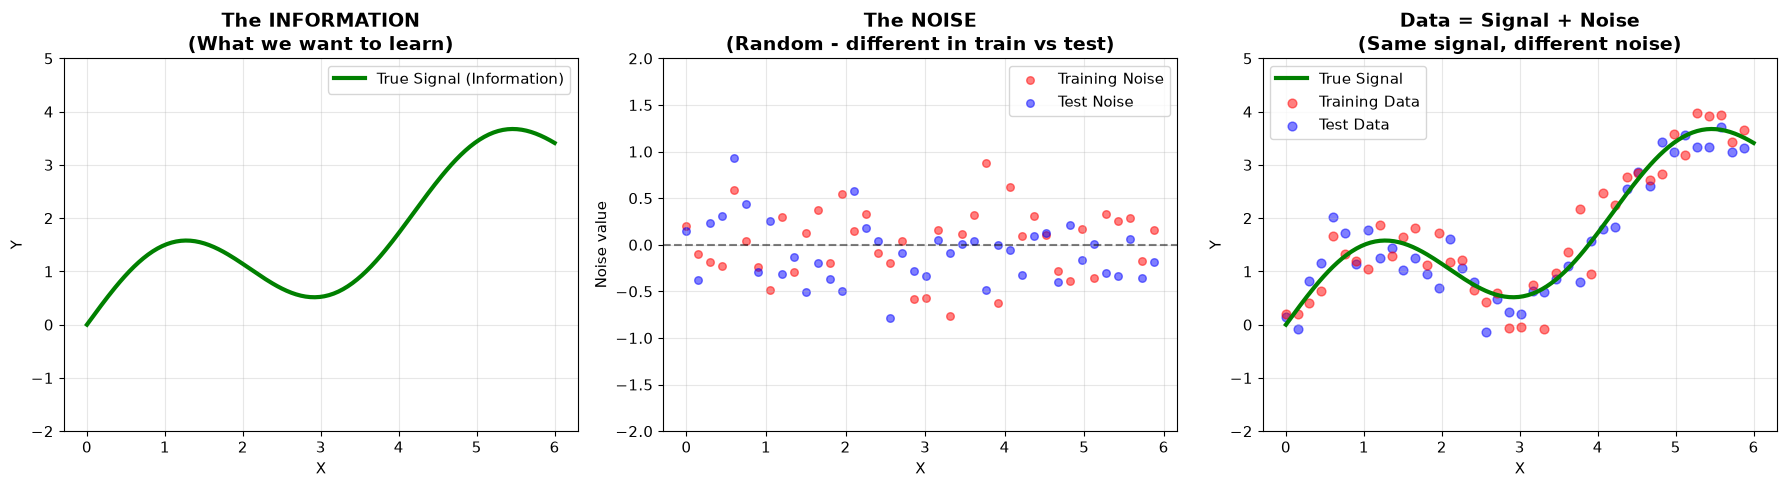

KEY INSIGHT:
  - Training and test data share the SAME underlying signal
  - But they have DIFFERENT random noise
  - If we learn the noise from training data, it won't help on test data!


In [2]:
def true_signal(x):
    """The TRUE underlying pattern - this is what we want to learn."""
    return 0.5 * x + np.sin(1.5 * x)

# Create x values
x = np.linspace(0, 6, 200)
signal = true_signal(x)

# Generate two different noise samples (representing train and test)
np.random.seed(42)
noise_train = np.random.normal(0, 0.4, len(x))
noise_test = np.random.normal(0, 0.4, len(x))  # DIFFERENT noise!

# Data = Signal + Noise
data_train = signal + noise_train
data_test = signal + noise_test

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: The True Signal (Information)
axes[0].plot(x, signal, 'g-', linewidth=3, label='True Signal (Information)')
axes[0].set_title('The INFORMATION\n(What we want to learn)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('X')
axes[0].set_ylabel('Y')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim(-2, 5)

# Plot 2: The Noise
axes[1].scatter(x[::5], noise_train[::5], c='red', alpha=0.5, s=30, label='Training Noise')
axes[1].scatter(x[::5], noise_test[::5], c='blue', alpha=0.5, s=30, label='Test Noise')
axes[1].axhline(y=0, color='black', linestyle='--', alpha=0.5)
axes[1].set_title('The NOISE\n(Random - different in train vs test)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('X')
axes[1].set_ylabel('Noise value')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim(-2, 2)

# Plot 3: Signal + Noise = Data
axes[2].plot(x, signal, 'g-', linewidth=3, label='True Signal', zorder=3)
axes[2].scatter(x[::5], data_train[::5], c='red', alpha=0.5, s=40, label='Training Data', zorder=2)
axes[2].scatter(x[::5], data_test[::5], c='blue', alpha=0.5, s=40, label='Test Data', zorder=1)
axes[2].set_title('Data = Signal + Noise\n(Same signal, different noise)', fontsize=14, fontweight='bold')
axes[2].set_xlabel('X')
axes[2].set_ylabel('Y')
axes[2].legend()
axes[2].grid(True, alpha=0.3)
axes[2].set_ylim(-2, 5)

plt.tight_layout()
plt.show()

print("KEY INSIGHT:")
print("  - Training and test data share the SAME underlying signal")
print("  - But they have DIFFERENT random noise")
print("  - If we learn the noise from training data, it won't help on test data!")

---
## 3. The Three Scenarios: Underfit, Just Right, Overfit

Now let's see how different model complexities capture (or fail to capture) the signal.

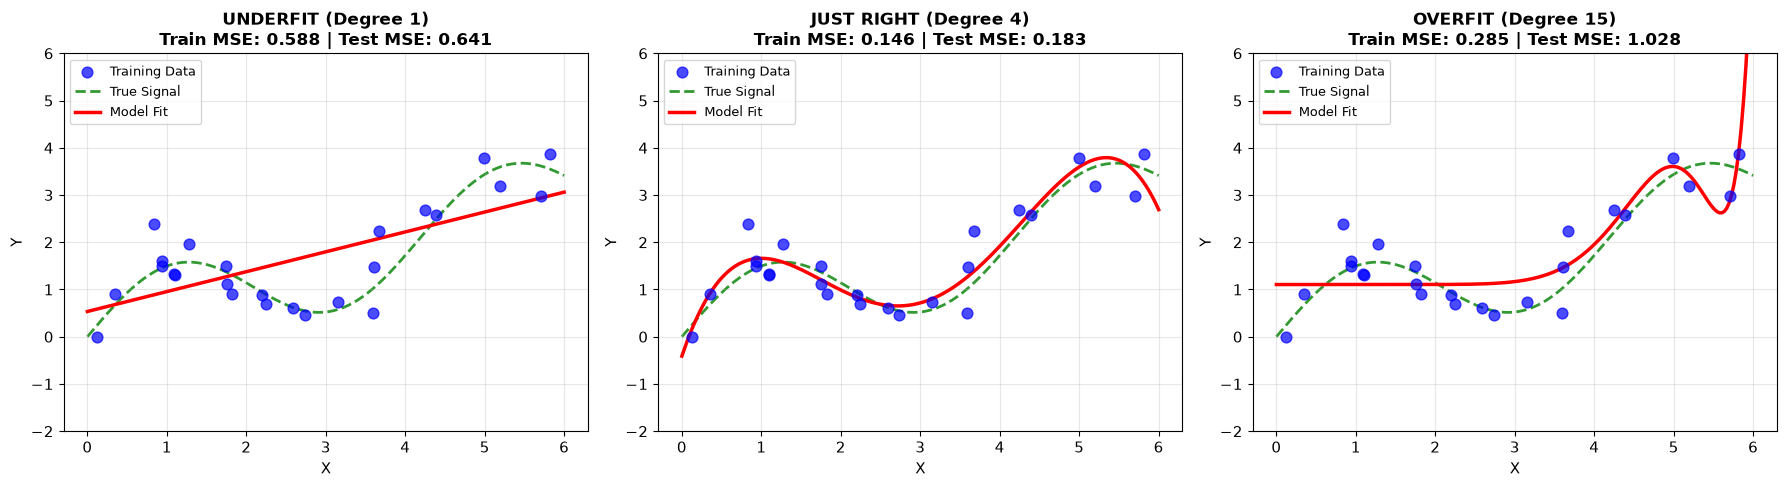

OBSERVATIONS:

  UNDERFIT (Left):
    - Model is TOO SIMPLE (just a line)
    - Cannot capture the curved signal
    - Both train and test errors are HIGH

  JUST RIGHT (Middle):
    - Model captures the TRUE SIGNAL well
    - Ignores the noise (doesn't wiggle through each point)
    - Both train and test errors are LOW and SIMILAR

  OVERFIT (Right):
    - Model is TOO COMPLEX (wiggly line)
    - Fits the NOISE in training data
    - Train error is VERY LOW, test error is HIGH


In [3]:
# Generate training and test data
np.random.seed(42)
n_train = 25
n_test = 50

# Training data
X_train = np.sort(np.random.uniform(0, 6, n_train))
y_train = true_signal(X_train) + np.random.normal(0, 0.4, n_train)

# Test data (SAME signal, DIFFERENT noise)
X_test = np.linspace(0, 6, n_test)
np.random.seed(99)  # Different seed = different noise
y_test = true_signal(X_test) + np.random.normal(0, 0.4, n_test)

# Dense x for smooth plotting
X_plot = np.linspace(0, 6, 200)
y_true = true_signal(X_plot)

# Three models with different complexity
models = {
    'UNDERFIT (Degree 1)': 1,   # Too simple - linear
    'JUST RIGHT (Degree 4)': 4,  # Captures the pattern
    'OVERFIT (Degree 15)': 15    # Too complex - fits noise
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, degree) in zip(axes, models.items()):
    # Fit polynomial model
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train.reshape(-1, 1))
    X_test_poly = poly.transform(X_test.reshape(-1, 1))
    X_plot_poly = poly.transform(X_plot.reshape(-1, 1))
    
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    
    # Predictions
    y_pred_train = model.predict(X_train_poly)
    y_pred_test = model.predict(X_test_poly)
    y_pred_plot = model.predict(X_plot_poly)
    
    # Errors
    train_mse = mean_squared_error(y_train, y_pred_train)
    test_mse = mean_squared_error(y_test, y_pred_test)
    
    # Plot
    ax.scatter(X_train, y_train, c='blue', s=60, alpha=0.7, label='Training Data', zorder=3)
    ax.plot(X_plot, y_true, 'g--', linewidth=2, label='True Signal', alpha=0.8, zorder=1)
    ax.plot(X_plot, y_pred_plot, 'r-', linewidth=2.5, label='Model Fit', zorder=2)
    
    ax.set_title(f'{name}\nTrain MSE: {train_mse:.3f} | Test MSE: {test_mse:.3f}', 
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(-2, 6)

plt.tight_layout()
plt.show()

print("OBSERVATIONS:")
print("\n  UNDERFIT (Left):")
print("    - Model is TOO SIMPLE (just a line)")
print("    - Cannot capture the curved signal")
print("    - Both train and test errors are HIGH")
print("\n  JUST RIGHT (Middle):")
print("    - Model captures the TRUE SIGNAL well")
print("    - Ignores the noise (doesn't wiggle through each point)")
print("    - Both train and test errors are LOW and SIMILAR")
print("\n  OVERFIT (Right):")
print("    - Model is TOO COMPLEX (wiggly line)")
print("    - Fits the NOISE in training data")
print("    - Train error is VERY LOW, test error is HIGH")

---
## 4. Why Overfitting Fails: The Noise is Different!

The key insight: when a model learns noise from training data, it expects that SAME noise pattern in test data. But test data has DIFFERENT noise!

In [4]:
def show_noise_mismatch(random_seed_test=99):
    """Show how overfitted model fails because it learned training noise."""
    
    # Training data (fixed)
    np.random.seed(42)
    X_train = np.sort(np.random.uniform(0, 6, 15))
    y_train_signal = true_signal(X_train)
    y_train_noise = np.random.normal(0, 0.5, len(X_train))
    y_train = y_train_signal + y_train_noise
    
    # Test data (different noise!)
    X_test = X_train.copy()  # Same x locations
    y_test_signal = true_signal(X_test)  # Same signal
    np.random.seed(random_seed_test)  # Different noise!
    y_test_noise = np.random.normal(0, 0.5, len(X_test))
    y_test = y_test_signal + y_test_noise
    
    # Fit overcomplex model (degree 14 for 15 points = nearly perfect fit)
    poly = PolynomialFeatures(degree=12)
    X_train_poly = poly.fit_transform(X_train.reshape(-1, 1))
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    
    # Predictions
    X_plot = np.linspace(0, 6, 200)
    X_plot_poly = poly.transform(X_plot.reshape(-1, 1))
    y_pred = model.predict(X_plot_poly)
    
    X_test_poly = poly.transform(X_test.reshape(-1, 1))
    y_pred_test = model.predict(X_test_poly)
    
    # Calculate errors
    train_mse = mean_squared_error(y_train, model.predict(X_train_poly))
    test_mse = mean_squared_error(y_test, y_pred_test)
    
    # Visualization
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Plot 1: What the model learned
    axes[0].scatter(X_train, y_train, c='blue', s=100, zorder=3, label='Training Points')
    axes[0].plot(X_plot, true_signal(X_plot), 'g--', linewidth=2, label='True Signal', alpha=0.8)
    axes[0].plot(X_plot, y_pred, 'r-', linewidth=2, label='Overfit Model')
    axes[0].set_title('What the Model Learned\n(Fits training data perfectly)', fontsize=12, fontweight='bold')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[0].set_ylim(-3, 7)
    
    # Plot 2: The noise comparison
    width = 0.2
    x_pos = np.arange(len(X_train))
    axes[1].bar(x_pos - width/2, y_train_noise, width, label='Training Noise', color='blue', alpha=0.7)
    axes[1].bar(x_pos + width/2, y_test_noise, width, label='Test Noise', color='red', alpha=0.7)
    axes[1].axhline(y=0, color='black', linestyle='--', alpha=0.5)
    axes[1].set_title('The Noise is DIFFERENT!\n(Train noise vs Test noise)', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Data Point Index')
    axes[1].set_ylabel('Noise Value')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3, axis='y')
    
    # Plot 3: Prediction errors on test data
    axes[2].scatter(X_test, y_test, c='red', s=100, zorder=3, label='Test Data (different noise)')
    axes[2].plot(X_plot, y_pred, 'r-', linewidth=2, label='Overfit Model', alpha=0.8)
    
    # Draw error lines
    for i in range(len(X_test)):
        axes[2].plot([X_test[i], X_test[i]], [y_test[i], y_pred_test[i]], 
                     'k-', linewidth=1.5, alpha=0.5)
    
    axes[2].set_title(f'Why It Fails on Test Data\nTrain MSE: {train_mse:.3f} | Test MSE: {test_mse:.3f}', 
                      fontsize=12, fontweight='bold')
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)
    axes[2].set_ylim(-3, 7)
    
    plt.tight_layout()
    plt.show()
    
    print(f"\nNOISE CORRELATION: {np.corrcoef(y_train_noise, y_test_noise)[0,1]:.3f}")
    print("  (Should be near 0 - noise is random and uncorrelated!)")
    print(f"\nThe model learned to expect training noise, but test data has DIFFERENT noise.")
    print(f"Result: Model predictions are way off!")

# Interactive: try different test noise seeds
interact(show_noise_mismatch, 
         random_seed_test=IntSlider(value=99, min=1, max=200, step=1, 
                                    description='Test Noise Seed'));

interactive(children=(IntSlider(value=99, description='Test Noise Seed', max=200, min=1), Output()), _dom_clas…

---
## 5. Interactive Exploration: Model Complexity vs Performance

Use the slider to see how model complexity affects the ability to capture signal vs noise.

In [5]:
def interactive_complexity_demo(degree=1, noise_level=0.4):
    """Interactive demonstration of how complexity affects learning."""
    
    # Generate data
    np.random.seed(42)
    n_train = 25
    X_train = np.sort(np.random.uniform(0, 6, n_train))
    y_train = true_signal(X_train) + np.random.normal(0, noise_level, n_train)
    
    np.random.seed(123)
    n_test = 100
    X_test = np.linspace(0, 6, n_test)
    y_test = true_signal(X_test) + np.random.normal(0, noise_level, n_test)
    
    # Fit model
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train.reshape(-1, 1))
    X_test_poly = poly.transform(X_test.reshape(-1, 1))
    
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    
    y_pred_train = model.predict(X_train_poly)
    y_pred_test = model.predict(X_test_poly)
    
    # Smooth prediction line
    X_plot = np.linspace(0, 6, 300)
    X_plot_poly = poly.transform(X_plot.reshape(-1, 1))
    y_pred_plot = model.predict(X_plot_poly)
    
    # Errors
    train_mse = mean_squared_error(y_train, y_pred_train)
    test_mse = mean_squared_error(y_test, y_pred_test)
    signal_mse = mean_squared_error(true_signal(X_test), y_pred_test)  # Error from true signal
    
    # Visualization
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Left: Model fit
    axes[0].scatter(X_train, y_train, c='blue', s=60, alpha=0.7, label='Training Data', zorder=3)
    axes[0].plot(X_plot, true_signal(X_plot), 'g--', linewidth=2.5, label='True Signal', alpha=0.8)
    axes[0].plot(X_plot, y_pred_plot, 'r-', linewidth=2.5, label=f'Model (degree {degree})')
    axes[0].set_xlabel('X', fontsize=12)
    axes[0].set_ylabel('Y', fontsize=12)
    axes[0].legend(fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].set_ylim(-3, 7)
    
    # Determine status
    if degree <= 2:
        status = "UNDERFIT"
        color = "red"
        explanation = "Model too simple - missing the signal"
    elif degree <= 6:
        status = "GOOD FIT"
        color = "green"
        explanation = "Model captures signal, ignores noise"
    else:
        status = "OVERFIT"
        color = "orange"
        explanation = "Model learning noise, not just signal"
    
    axes[0].set_title(f'{status}: {explanation}', fontsize=14, fontweight='bold', color=color)
    
    # Right: Error comparison
    errors = [train_mse, test_mse, signal_mse]
    labels = ['Train Error', 'Test Error', 'Error from\nTrue Signal']
    colors = ['skyblue', 'salmon', 'lightgreen']
    
    bars = axes[1].bar(labels, errors, color=colors, alpha=0.8, edgecolor='black')
    
    # Add value labels
    for bar, error in zip(bars, errors):
        height = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width()/2., height + 0.02,
                     f'{error:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=11)
    
    # Add irreducible error line
    irreducible = noise_level ** 2
    axes[1].axhline(y=irreducible, color='gray', linestyle='--', linewidth=2, 
                    label=f'Irreducible Error ({irreducible:.3f})')
    
    axes[1].set_ylabel('Mean Squared Error', fontsize=12)
    axes[1].set_title('Performance Metrics', fontsize=14, fontweight='bold')
    axes[1].legend(loc='upper right', fontsize=10)
    axes[1].grid(True, alpha=0.3, axis='y')
    axes[1].set_ylim(0, max(errors) * 1.3)
    
    plt.tight_layout()
    plt.show()
    
    # Diagnosis
    gap = test_mse - train_mse
    print("DIAGNOSIS:")
    print(f"  Model Parameters: {X_train_poly.shape[1]} (polynomial degree {degree})")
    print(f"  Training Points: {n_train}")
    print(f"  Train MSE: {train_mse:.4f}")
    print(f"  Test MSE: {test_mse:.4f}")
    print(f"  Gap (Test - Train): {gap:.4f}")
    print(f"  Error from True Signal: {signal_mse:.4f}")
    print(f"\n  STATUS: {status}")
    
    if status == "UNDERFIT":
        print("  - Both errors high because model doesn't capture the pattern")
        print("  - Solution: Increase model complexity")
    elif status == "GOOD FIT":
        print("  - Low error on both train and test")
        print("  - Model has learned the true signal!")
    else:
        print("  - Train error much lower than test error")
        print("  - Model is memorizing noise in training data")
        print("  - Solution: Reduce complexity or get more data")

# Interactive widget
interact(interactive_complexity_demo,
         degree=IntSlider(value=1, min=1, max=20, step=1, description='Complexity'),
         noise_level=FloatSlider(value=0.4, min=0.1, max=1.0, step=0.1, description='Noise'));

interactive(children=(IntSlider(value=1, description='Complexity', max=20, min=1), FloatSlider(value=0.4, desc…

---
## 6. The Classic U-Shaped Curve

As model complexity increases:
- Training error **always decreases** (more parameters = better fit to training data)
- Test error **first decreases, then increases** (U-shape)

The optimal complexity is at the bottom of the U!

In [6]:
def plot_complexity_curve(noise_level=0.4, n_train=25):
    """Plot training and test error vs model complexity."""
    
    # Generate data
    np.random.seed(42)
    X_train = np.sort(np.random.uniform(0, 6, n_train))
    y_train = true_signal(X_train) + np.random.normal(0, noise_level, n_train)
    
    np.random.seed(123)
    X_test = np.linspace(0, 6, 100)
    y_test = true_signal(X_test) + np.random.normal(0, noise_level, 100)
    y_true = true_signal(X_test)
    
    # Test different complexities
    degrees = range(1, 16)
    train_errors = []
    test_errors = []
    signal_errors = []  # How well model matches true signal (without noise)
    
    for degree in degrees:
        poly = PolynomialFeatures(degree=degree)
        X_train_poly = poly.fit_transform(X_train.reshape(-1, 1))
        X_test_poly = poly.transform(X_test.reshape(-1, 1))
        
        model = LinearRegression()
        model.fit(X_train_poly, y_train)
        
        train_errors.append(mean_squared_error(y_train, model.predict(X_train_poly)))
        test_errors.append(mean_squared_error(y_test, model.predict(X_test_poly)))
        signal_errors.append(mean_squared_error(y_true, model.predict(X_test_poly)))
    
    # Find optimal complexity
    optimal_idx = np.argmin(test_errors)
    optimal_degree = degrees[optimal_idx]
    
    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Left: Training vs Test Error
    axes[0].plot(degrees, train_errors, 'o-', linewidth=2, markersize=8, 
                 label='Training Error', color='blue')
    axes[0].plot(degrees, test_errors, 's-', linewidth=2, markersize=8, 
                 label='Test Error', color='red')
    axes[0].axhline(y=noise_level**2, color='gray', linestyle='--', linewidth=2, 
                    label=f'Irreducible Error ({noise_level**2:.3f})')
    axes[0].axvline(x=optimal_degree, color='green', linestyle='--', linewidth=2, 
                    label=f'Optimal (degree {optimal_degree})')
    
    # Shade regions
    axes[0].axvspan(1, optimal_degree - 0.3, alpha=0.15, color='blue', label='Underfit Region')
    axes[0].axvspan(optimal_degree + 0.3, 15, alpha=0.15, color='red', label='Overfit Region')
    
    axes[0].set_xlabel('Model Complexity (Polynomial Degree)', fontsize=12)
    axes[0].set_ylabel('Mean Squared Error', fontsize=12)
    axes[0].set_title('The U-Shaped Test Error Curve', fontsize=14, fontweight='bold')
    axes[0].legend(loc='upper right', fontsize=9)
    axes[0].grid(True, alpha=0.3)
    axes[0].set_xticks(list(degrees))
    
    # Right: What model learned (signal vs noise)
    # The gap between test error and signal error shows how much noise the model learned
    noise_learned = np.array(train_errors)  # Lower train error = more noise learned
    signal_captured = np.array(signal_errors)  # Lower = better signal capture
    
    axes[1].plot(degrees, signal_errors, 'o-', linewidth=2, markersize=8, 
                 label='Error from True Signal', color='green')
    axes[1].fill_between(degrees, 0, signal_errors, alpha=0.2, color='green', 
                         label='Signal NOT captured')
    axes[1].axhline(y=0, color='black', linestyle='-', alpha=0.3)
    axes[1].axvline(x=optimal_degree, color='green', linestyle='--', linewidth=2)
    
    axes[1].set_xlabel('Model Complexity (Polynomial Degree)', fontsize=12)
    axes[1].set_ylabel('MSE from True Signal', fontsize=12)
    axes[1].set_title('How Well Model Captures the TRUE Signal', fontsize=14, fontweight='bold')
    axes[1].legend(fontsize=10)
    axes[1].grid(True, alpha=0.3)
    axes[1].set_xticks(list(degrees))
    
    plt.tight_layout()
    plt.show()
    
    print(f"OPTIMAL COMPLEXITY: Degree {optimal_degree}")
    print(f"  - Best test error: {test_errors[optimal_idx]:.4f}")
    print(f"  - Irreducible error: {noise_level**2:.4f}")
    print(f"\nKEY OBSERVATIONS:")
    print(f"  - Training error ALWAYS decreases with complexity")
    print(f"  - Test error follows a U-shape")
    print(f"  - The gap between them shows overfitting")
    print(f"  - At high complexity, model fits noise, not signal")

interact(plot_complexity_curve,
         noise_level=FloatSlider(value=0.4, min=0.1, max=1.0, step=0.1, description='Noise'),
         n_train=IntSlider(value=25, min=10, max=100, step=5, description='Train Size'));

interactive(children=(FloatSlider(value=0.4, description='Noise', max=1.0, min=0.1), IntSlider(value=25, descr…

---
## 7. More Data Helps with Overfitting!

One of the best cures for overfitting is simply **more training data**. With more data, it becomes harder for the model to memorize noise.

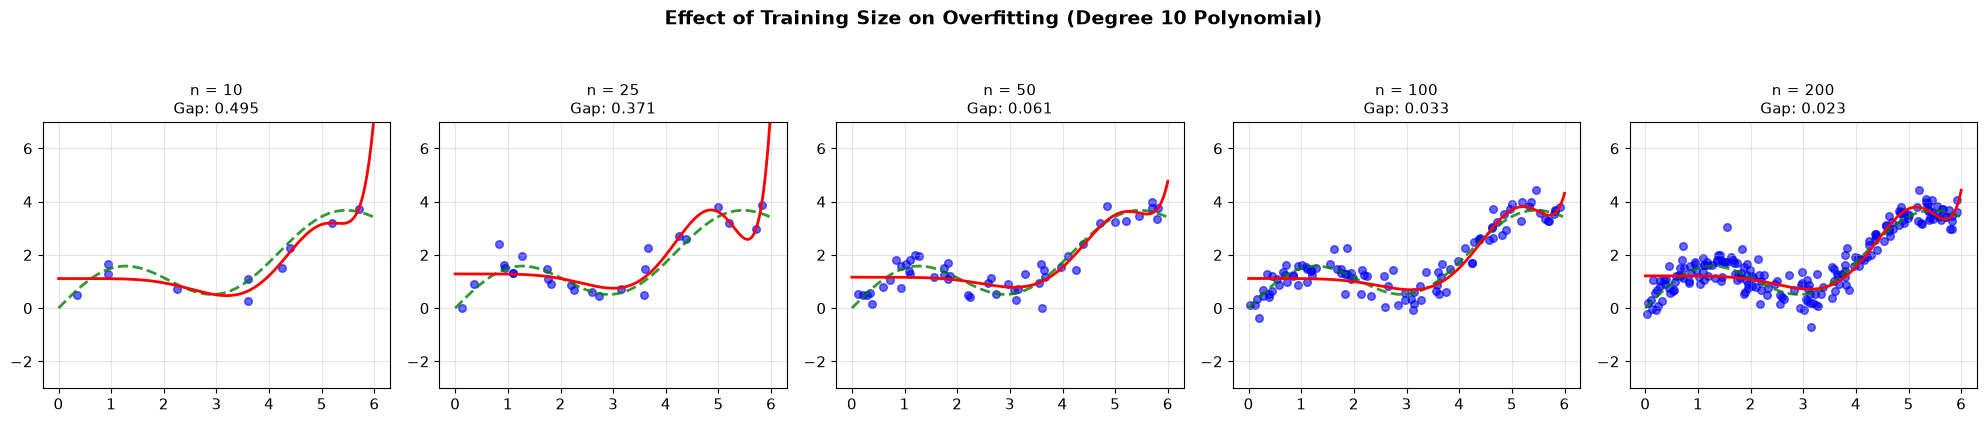

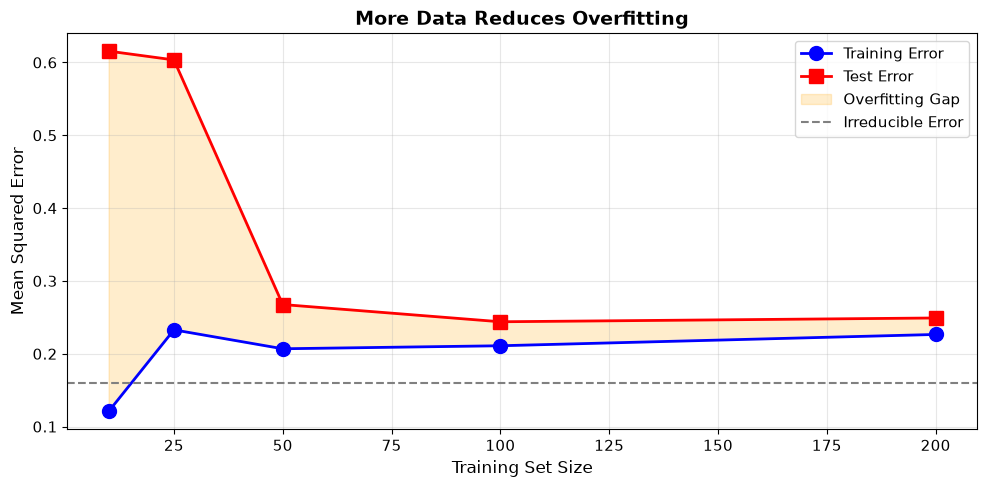

RESULTS:
     n   train    test     gap
0   10  0.1209  0.6156  0.4947
1   25  0.2329  0.6035  0.3706
2   50  0.2069  0.2676  0.0607
3  100  0.2110  0.2440  0.0329
4  200  0.2265  0.2492  0.0226

KEY INSIGHT:
  With MORE DATA, it's harder for the model to memorize noise.
  The training and test errors converge as data increases.
  This is one of the most effective ways to combat overfitting!


In [7]:
def show_data_size_effect():
    """Show how more data reduces overfitting."""
    
    sample_sizes = [10, 25, 50, 100, 200]
    degree = 10  # Complex model that overfits with small data
    
    # Fixed test set
    np.random.seed(999)
    X_test = np.linspace(0, 6, 100)
    y_test = true_signal(X_test) + np.random.normal(0, 0.4, 100)
    
    results = []
    
    fig, axes = plt.subplots(1, len(sample_sizes), figsize=(20, 4))
    
    for ax, n_train in zip(axes, sample_sizes):
        np.random.seed(42)
        X_train = np.sort(np.random.uniform(0, 6, n_train))
        y_train = true_signal(X_train) + np.random.normal(0, 0.4, n_train)
        
        # Fit model
        poly = PolynomialFeatures(degree=degree)
        X_train_poly = poly.fit_transform(X_train.reshape(-1, 1))
        X_test_poly = poly.transform(X_test.reshape(-1, 1))
        
        model = LinearRegression()
        model.fit(X_train_poly, y_train)
        
        train_mse = mean_squared_error(y_train, model.predict(X_train_poly))
        test_mse = mean_squared_error(y_test, model.predict(X_test_poly))
        
        results.append({'n': n_train, 'train': train_mse, 'test': test_mse, 'gap': test_mse - train_mse})
        
        # Plot
        X_plot = np.linspace(0, 6, 300)
        X_plot_poly = poly.transform(X_plot.reshape(-1, 1))
        y_pred = model.predict(X_plot_poly)
        
        ax.scatter(X_train, y_train, c='blue', s=30, alpha=0.6)
        ax.plot(X_plot, true_signal(X_plot), 'g--', linewidth=2, alpha=0.8)
        ax.plot(X_plot, y_pred, 'r-', linewidth=2)
        ax.set_title(f'n = {n_train}\nGap: {test_mse - train_mse:.3f}', fontsize=11)
        ax.set_ylim(-3, 7)
        ax.grid(True, alpha=0.3)
    
    plt.suptitle(f'Effect of Training Size on Overfitting (Degree {degree} Polynomial)', 
                 fontsize=14, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()
    
    # Summary plot
    results_df = pd.DataFrame(results)
    
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(results_df['n'], results_df['train'], 'o-', linewidth=2, markersize=10, 
            label='Training Error', color='blue')
    ax.plot(results_df['n'], results_df['test'], 's-', linewidth=2, markersize=10, 
            label='Test Error', color='red')
    ax.fill_between(results_df['n'], results_df['train'], results_df['test'], 
                    alpha=0.2, color='orange', label='Overfitting Gap')
    ax.axhline(y=0.16, color='gray', linestyle='--', label='Irreducible Error')
    
    ax.set_xlabel('Training Set Size', fontsize=12)
    ax.set_ylabel('Mean Squared Error', fontsize=12)
    ax.set_title('More Data Reduces Overfitting', fontsize=14, fontweight='bold')
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    print("RESULTS:")
    print(results_df.round(4))
    print("\nKEY INSIGHT:")
    print("  With MORE DATA, it's harder for the model to memorize noise.")
    print("  The training and test errors converge as data increases.")
    print("  This is one of the most effective ways to combat overfitting!")

show_data_size_effect()

---
## 8. Summary: Putting It All Together

### The Core Framework

```
Training Data = Information (Signal) + Random Noise (Sample 1)
Test Data     = Information (Signal) + Random Noise (Sample 2)
```

### The Three Scenarios

| Scenario | Model Learns | Train Error | Test Error | Solution |
|----------|-------------|-------------|------------|----------|
| **UNDERFIT** | Partial Information | High | High | Increase complexity |
| **JUST RIGHT** | All Information | Low | Low | You're done! |
| **OVERFIT** | Information + Noise | Very Low | High | Decrease complexity or add data |

### Why Overfitting Fails

When the model learns training noise:
1. It expects that exact noise pattern in new data
2. But test data has different, uncorrelated noise
3. So predictions are systematically wrong

### Detection Strategy

Compare training and test performance:
- **Both high?** Underfitting
- **Both low and similar?** Good fit
- **Train low, Test high?** Overfitting

### Prevention Strategies

1. **More training data** (reduces ability to memorize noise)
2. **Simpler model** (fewer parameters to fit noise)
3. **Regularization** (penalize model complexity)
4. **Cross-validation** (detect overfitting early)
5. **Early stopping** (stop before learning noise)

In [8]:
print("OVERFITTING VS UNDERFITTING: QUICK REFERENCE")
print("=" * 60)
print("\nDATA COMPOSITION:")
print("  Training Data = Signal + Noise (sample 1)")
print("  Test Data     = Signal + Noise (sample 2)  <- DIFFERENT noise!")
print("\nGOAL: Learn the SIGNAL, ignore the NOISE")
print("\n" + "-" * 60)
print("UNDERFITTING (High Bias):")
print("  What: Model too SIMPLE to capture the signal")
print("  Symptom: Both train and test errors are HIGH")
print("  Fix: Increase model complexity, add features")
print("\n" + "-" * 60)
print("OVERFITTING (High Variance):")
print("  What: Model memorizes NOISE along with signal")
print("  Symptom: Train error LOW, test error HIGH")
print("  Why it fails: Test data has DIFFERENT noise!")
print("  Fix: More data, simpler model, regularization")
print("\n" + "-" * 60)
print("JUST RIGHT:")
print("  What: Model captures signal, ignores noise")
print("  Symptom: Both train and test errors are LOW and SIMILAR")
print("  Result: Good generalization to new data!")

OVERFITTING VS UNDERFITTING: QUICK REFERENCE

DATA COMPOSITION:
  Training Data = Signal + Noise (sample 1)
  Test Data     = Signal + Noise (sample 2)  <- DIFFERENT noise!

GOAL: Learn the SIGNAL, ignore the NOISE

------------------------------------------------------------
UNDERFITTING (High Bias):
  What: Model too SIMPLE to capture the signal
  Symptom: Both train and test errors are HIGH
  Fix: Increase model complexity, add features

------------------------------------------------------------
OVERFITTING (High Variance):
  What: Model memorizes NOISE along with signal
  Symptom: Train error LOW, test error HIGH
  Why it fails: Test data has DIFFERENT noise!
  Fix: More data, simpler model, regularization

------------------------------------------------------------
JUST RIGHT:
  What: Model captures signal, ignores noise
  Symptom: Both train and test errors are LOW and SIMILAR
  Result: Good generalization to new data!


---
## 9. Practice Exercise

Use the interactive tool below to find the optimal model complexity for different noise levels.

In [9]:
def find_optimal_complexity(noise_level=0.4, n_train=30):
    """Find and visualize optimal model complexity."""
    
    np.random.seed(42)
    X_train = np.sort(np.random.uniform(0, 6, n_train))
    y_train = true_signal(X_train) + np.random.normal(0, noise_level, n_train)
    
    np.random.seed(123)
    X_test = np.linspace(0, 6, 100)
    y_test = true_signal(X_test) + np.random.normal(0, noise_level, 100)
    
    degrees = range(1, 20)
    test_errors = []
    
    for degree in degrees:
        poly = PolynomialFeatures(degree=degree)
        X_train_poly = poly.fit_transform(X_train.reshape(-1, 1))
        X_test_poly = poly.transform(X_test.reshape(-1, 1))
        
        model = LinearRegression()
        model.fit(X_train_poly, y_train)
        test_errors.append(mean_squared_error(y_test, model.predict(X_test_poly)))
    
    optimal_degree = degrees[np.argmin(test_errors)]
    
    # Show optimal model
    poly = PolynomialFeatures(degree=optimal_degree)
    X_train_poly = poly.fit_transform(X_train.reshape(-1, 1))
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    
    X_plot = np.linspace(0, 6, 200)
    X_plot_poly = poly.transform(X_plot.reshape(-1, 1))
    y_pred = model.predict(X_plot_poly)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    
    # Optimal model fit
    axes[0].scatter(X_train, y_train, c='blue', s=50, alpha=0.6, label='Training Data')
    axes[0].plot(X_plot, true_signal(X_plot), 'g--', linewidth=2, label='True Signal')
    axes[0].plot(X_plot, y_pred, 'r-', linewidth=2.5, label=f'Optimal Model (degree {optimal_degree})')
    axes[0].set_title(f'Optimal Complexity: Degree {optimal_degree}', fontsize=14, fontweight='bold')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[0].set_ylim(-3, 7)
    
    # Test error curve
    axes[1].plot(degrees, test_errors, 'o-', linewidth=2, markersize=6)
    axes[1].axvline(x=optimal_degree, color='green', linestyle='--', linewidth=2, 
                    label=f'Optimal: degree {optimal_degree}')
    axes[1].axhline(y=noise_level**2, color='gray', linestyle='--', alpha=0.7,
                    label=f'Irreducible: {noise_level**2:.3f}')
    axes[1].set_xlabel('Polynomial Degree')
    axes[1].set_ylabel('Test Error')
    axes[1].set_title('Test Error vs Complexity', fontsize=14, fontweight='bold')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    print(f"OPTIMAL COMPLEXITY FOUND: Degree {optimal_degree}")
    print(f"Best test error: {min(test_errors):.4f}")
    print(f"Irreducible error: {noise_level**2:.4f}")
    print(f"\nTry different noise levels and training sizes to see how optimal complexity changes!")

interact(find_optimal_complexity,
         noise_level=FloatSlider(value=0.4, min=0.1, max=1.0, step=0.1, description='Noise Level'),
         n_train=IntSlider(value=30, min=15, max=100, step=5, description='Training Size'));

interactive(children=(FloatSlider(value=0.4, description='Noise Level', max=1.0, min=0.1), IntSlider(value=30,…

---

## Congratulations!

You now understand the fundamental concepts of overfitting and underfitting from the signal vs. noise perspective:

1. **Data = Signal + Noise**
2. **Goal: Learn signal, ignore noise**
3. **Underfit: Missing the signal**
4. **Overfit: Learning the noise**
5. **Different test noise = poor generalization**

This intuition will guide you in selecting appropriate model complexity and diagnosing problems in your machine learning projects.

---